In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство вычислений: {device}")

Устройство вычислений: cuda


In [2]:
cifar10_mean = (0.4914, 0.4822, 0.4465)
cifar10_std = (0.2023, 0.1994, 0.2010)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(cifar10_mean, cifar10_std)
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar10_mean, cifar10_std)
])

train_dataset = datasets.CIFAR10(root="./data", train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root="./data", train=False, download=True, transform=test_transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

sample_image, sample_label = train_dataset[0]
sample_batch_images, sample_batch_labels = next(iter(train_loader))

print(f"Количество примеров в тренировочной выборке: {len(train_dataset)}")
print(f"Количество примеров в тестовой выборке: {len(test_dataset)}")
print(f"Количество классов: {len(train_dataset.classes)}")
print(f"Форма одного изображения (C, H, W): {tuple(sample_image.shape)}")
print(f"Тип и значение одной метки класса: {type(sample_label).__name__} ({sample_label})")
print(f"Форма пачки изображений (B, C, H, W): {tuple(sample_batch_images.shape)}")
print(f"Форма пачки меток (B,): {tuple(sample_batch_labels.shape)}")

Количество примеров в тренировочной выборке: 50000
Количество примеров в тестовой выборке: 10000
Количество классов: 10
Форма одного изображения (C, H, W): (3, 32, 32)
Тип и значение одной метки класса: int (6)
Форма пачки изображений (B, C, H, W): (128, 3, 32, 32)
Форма пачки меток (B,): (128,)


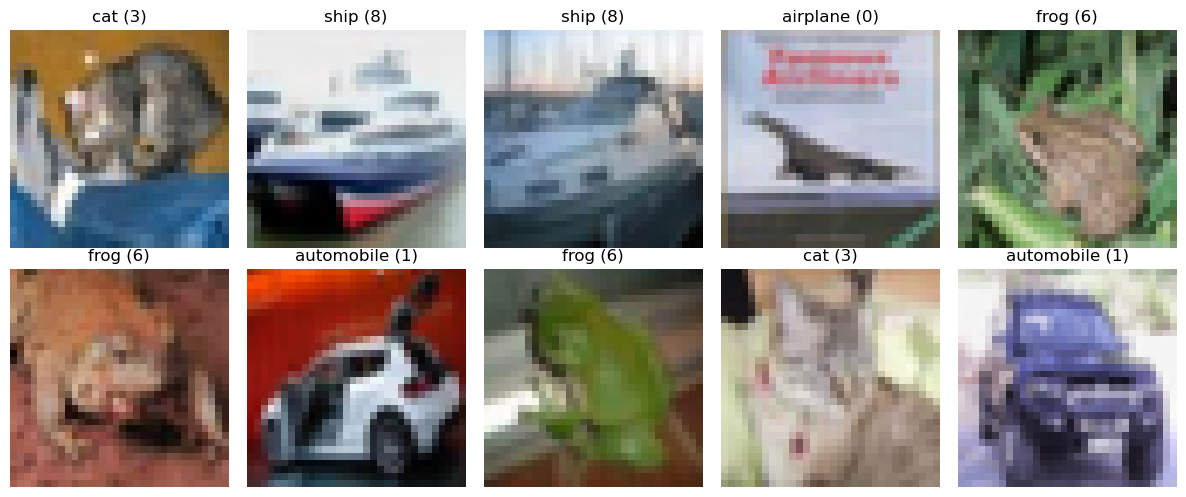

In [3]:
classes = train_dataset.classes

def denormalize(tensor, mean, std):
    mean_tensor = torch.tensor(mean).view(3, 1, 1)
    std_tensor = torch.tensor(std).view(3, 1, 1)
    return torch.clamp(tensor * std_tensor + mean_tensor, 0, 1)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    img_tensor, label_idx = test_dataset[i]
    img_vis = denormalize(img_tensor, cifar10_mean, cifar10_std).permute(1, 2, 0).numpy()
    ax.imshow(img_vis)
    ax.set_title(f"{classes[label_idx]} ({label_idx})")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
def conv_bn_relu(in_channels, out_channels, pool=False):
    layers = [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    ]
    if pool:
        layers.append(nn.MaxPool2d(kernel_size=2, stride=2))
    return nn.Sequential(*layers)

class CustomResNet9(nn.Module):
    def __init__(self, in_channels=3, num_classes=10):
        super().__init__()
        self.conv1 = conv_bn_relu(in_channels, 64)
        self.conv2 = conv_bn_relu(64, 128, pool=True)
        self.res1 = nn.Sequential(
            conv_bn_relu(128, 128),
            conv_bn_relu(128, 128)
        )
        self.conv3 = conv_bn_relu(128, 256, pool=True)
        self.conv4 = conv_bn_relu(256, 512, pool=True)
        self.res2 = nn.Sequential(
            conv_bn_relu(512, 512),
            conv_bn_relu(512, 512)
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveMaxPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.res1(out) + out
        out = self.conv3(out)
        out = self.conv4(out)
        out = self.res2(out) + out
        out = self.classifier(out)
        return out

model = CustomResNet9(in_channels=3, num_classes=10).to(device)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Количество обучаемых параметров модели: {total_params:,}")

Количество обучаемых параметров модели: 6,573,130


In [5]:
epochs = 30
max_lr = 0.01
weight_decay = 1e-2

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=max_lr, weight_decay=weight_decay)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=max_lr,
    epochs=epochs,
    steps_per_epoch=len(train_loader)
)

In [6]:
train_losses = []
train_accuracies = []

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_acc)

    print(f"Эпоха [{epoch:02d}/{epochs:02d}] | Ошибка (Train Loss): {epoch_loss:.4f} | Точность (Train Acc): {epoch_acc:.2f}%")

Эпоха [01/30] | Ошибка (Train Loss): 1.3572 | Точность (Train Acc): 52.61%
Эпоха [02/30] | Ошибка (Train Loss): 0.8907 | Точность (Train Acc): 68.84%
Эпоха [03/30] | Ошибка (Train Loss): 0.7912 | Точность (Train Acc): 73.20%
Эпоха [04/30] | Ошибка (Train Loss): 0.7704 | Точность (Train Acc): 74.43%
Эпоха [05/30] | Ошибка (Train Loss): 0.7277 | Точность (Train Acc): 75.78%
Эпоха [06/30] | Ошибка (Train Loss): 0.6235 | Точность (Train Acc): 79.37%
Эпоха [07/30] | Ошибка (Train Loss): 0.5297 | Точность (Train Acc): 82.14%
Эпоха [08/30] | Ошибка (Train Loss): 0.4679 | Точность (Train Acc): 84.36%
Эпоха [09/30] | Ошибка (Train Loss): 0.4317 | Точность (Train Acc): 85.30%
Эпоха [10/30] | Ошибка (Train Loss): 0.3955 | Точность (Train Acc): 86.60%
Эпоха [11/30] | Ошибка (Train Loss): 0.3632 | Точность (Train Acc): 87.74%
Эпоха [12/30] | Ошибка (Train Loss): 0.3398 | Точность (Train Acc): 88.33%
Эпоха [13/30] | Ошибка (Train Loss): 0.3057 | Точность (Train Acc): 89.58%
Эпоха [14/30] | Ошибка (T

In [7]:
model.eval()
test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        test_total += labels.size(0)
        test_correct += predicted.eq(labels).sum().item()

final_test_loss = test_loss / test_total
final_test_acc = 100.0 * test_correct / test_total

print(f"Итоговая ошибка на тестовой выборке (Test Loss): {final_test_loss:.4f}")
print(f"Итоговая точность на тестовой выборке (Test Accuracy): {final_test_acc:.2f}%")

Итоговая ошибка на тестовой выборке (Test Loss): 0.2776
Итоговая точность на тестовой выборке (Test Accuracy): 93.27%


Доля неверных ответов (Test Error): 6.73%


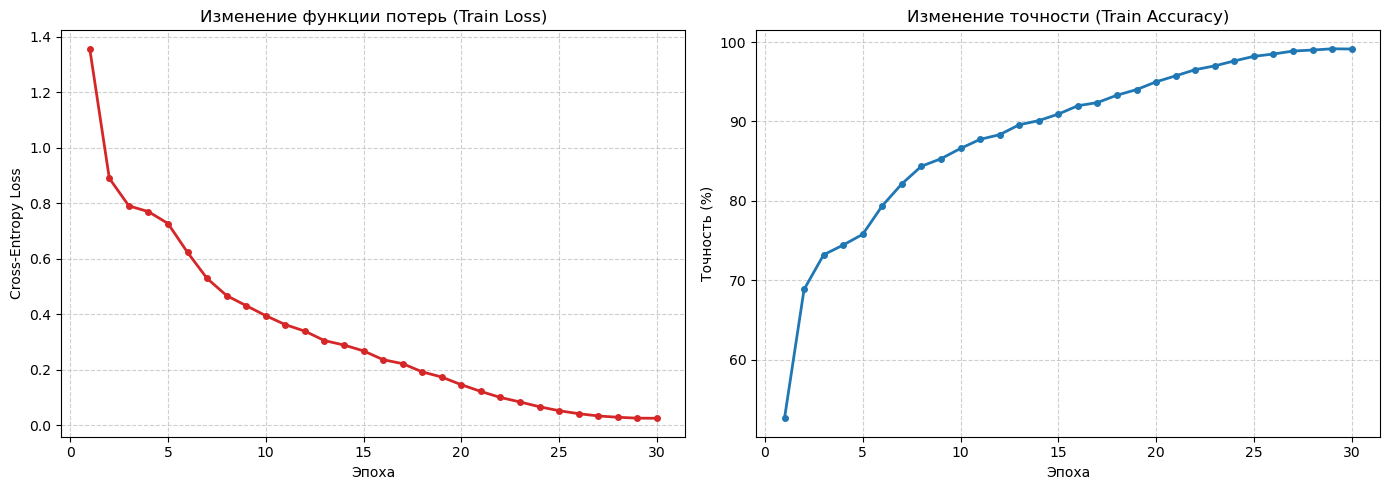

In [16]:
final_test_error = 100.0 - final_test_acc
print(f"Доля неверных ответов (Test Error): {final_test_error:.2f}%")

epochs_range = range(1, epochs + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, train_losses, marker="o", color="tab:red", linewidth=2, markersize=4)
ax1.set_title("Изменение функции потерь (Train Loss)")
ax1.set_xlabel("Эпоха")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(epochs_range, train_accuracies, marker="o", color="tab:blue", linewidth=2, markersize=4)
ax2.set_title("Изменение точности (Train Accuracy)")
ax2.set_xlabel("Эпоха")
ax2.set_ylabel("Точность (%)")
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()